In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import trange
from scipy.ndimage import zoom
from scipy.signal import medfilt2d
from scipy.ndimage import label
from skimage.measure import regionprops
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.ndimage import gaussian_filter
from RF_FUNCTIONS import *

In [33]:
plt.rcParams.update({
    "font.size": 19,            # base font size
    "axes.titlesize":19,       # titles
    "axes.labelsize": 19,       # x/y labels
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 22,
    "figure.titlesize": 22,
})

In [34]:
# Load dataset
spike_t_matrix=np.load('spike_t_matrix.npy',allow_pickle=True) # Spike time matrix for units from a single probe shape: (unit,spike_times)
g_ids=np.load('g_ids.npy') # ID numbers of recorded units
g_channels=np.load('g_channels.npy') # Corresponding peak channels on the probe
stim_windows=np.load('stim_windows.npy') # Stimulus frames display times (start,end)

sparse_noise_matrix=np.load('sparse_noise_matrix.npy') # Stimulus matrix shape:(n_noise_frames,height,width)
sparse_noise_matrix = sparse_noise_matrix[:len(stim_windows)] #In case stimulus terminated prematurely
sparse_noise_matrix_null = np.copy(sparse_noise_matrix) #Null matrix for comparison
np.random.shuffle(sparse_noise_matrix_null)  # shuffle along time axis

In [35]:
# Compute spike counts per stimulus (stim_unit_FRs)
n_units = len(g_ids)
n_stim = len(stim_windows)

stim_unit_FRs = np.zeros((n_units, n_stim), dtype=float)
stim_length = np.mean(np.diff(stim_windows, axis=1))  # seconds

print("Counting spikes per stimulus window...")
for unit in trange(n_units):
    spikes = spike_t_matrix[unit]
    for spike_t in spikes:
        if spike_t > stim_windows[0, 0] and spike_t < stim_windows[-1, 1] + 0.03:
            window_index = np.searchsorted(stim_windows[:, 0], spike_t) - 1
            if 0 <= window_index < n_stim and spike_t < stim_windows[window_index, 1] + 0.03:
                stim_unit_FRs[unit, window_index] += 1

Counting spikes per stimulus window...


100%|██████████| 24/24 [00:00<00:00, 45.74it/s]


In [36]:
# Build ON / OFF response matrices

ABS_sparse_matrix = np.abs(sparse_noise_matrix)
ABS_sparse_matrix = np.sum(ABS_sparse_matrix, axis=0)

positive_matrix = np.copy(sparse_noise_matrix)
positive_matrix[positive_matrix < 0] = 0
positive_sum_matrix = np.sum(positive_matrix, axis=0)  # denominator for ON

negative_matrix = np.copy(sparse_noise_matrix)
negative_matrix[negative_matrix > 0] = 0
negative_sum_matrix = -np.sum(negative_matrix, axis=0)  # denominator for OFF

# Initialize responses: (unit, height, width)
height, width = sparse_noise_matrix.shape[1], sparse_noise_matrix.shape[2]
UNIT_ON_RESPONSES = np.zeros((n_units, height, width), dtype=float)
UNIT_OFF_RESPONSES = np.zeros_like(UNIT_ON_RESPONSES)
UNIT_ON_RESPONSES_NULL = np.zeros_like(UNIT_ON_RESPONSES)
UNIT_OFF_RESPONSES_NULL = np.zeros_like(UNIT_OFF_RESPONSES)

print("Accumulating ON/OFF responses...")
for unit in trange(n_units):
    for stim_idx in range(n_stim):
        fr = stim_unit_FRs[unit, stim_idx]

        # ON / OFF actual
        temp_on = sparse_noise_matrix[stim_idx] > 0
        temp_off = sparse_noise_matrix[stim_idx] < 0

        UNIT_ON_RESPONSES[unit] += temp_on * fr
        UNIT_OFF_RESPONSES[unit] += temp_off * fr

        # ON / OFF null
        temp_on_null = sparse_noise_matrix_null[stim_idx] > 0
        temp_off_null = sparse_noise_matrix_null[stim_idx] < 0

        UNIT_ON_RESPONSES_NULL[unit] += temp_on_null * fr
        UNIT_OFF_RESPONSES_NULL[unit] += temp_off_null * fr

    # Normalize by positive / negative sums 
    UNIT_ON_RESPONSES[unit] = np.divide(
        UNIT_ON_RESPONSES[unit],
        positive_sum_matrix,
        out=np.zeros_like(UNIT_ON_RESPONSES[unit]),
        where=positive_sum_matrix != 0
    )
    UNIT_OFF_RESPONSES[unit] = np.divide(
        UNIT_OFF_RESPONSES[unit],
        negative_sum_matrix,
        out=np.zeros_like(UNIT_OFF_RESPONSES[unit]),
        where=negative_sum_matrix != 0
    )
    UNIT_ON_RESPONSES_NULL[unit] = np.divide(
        UNIT_ON_RESPONSES_NULL[unit],
        positive_sum_matrix,
        out=np.zeros_like(UNIT_ON_RESPONSES_NULL[unit]),
        where=positive_sum_matrix != 0
    )
    UNIT_OFF_RESPONSES_NULL[unit] = np.divide(
        UNIT_OFF_RESPONSES_NULL[unit],
        negative_sum_matrix,
        out=np.zeros_like(UNIT_OFF_RESPONSES_NULL[unit]),
        where=negative_sum_matrix != 0
    )

Accumulating ON/OFF responses...


100%|██████████| 24/24 [00:12<00:00,  1.96it/s]


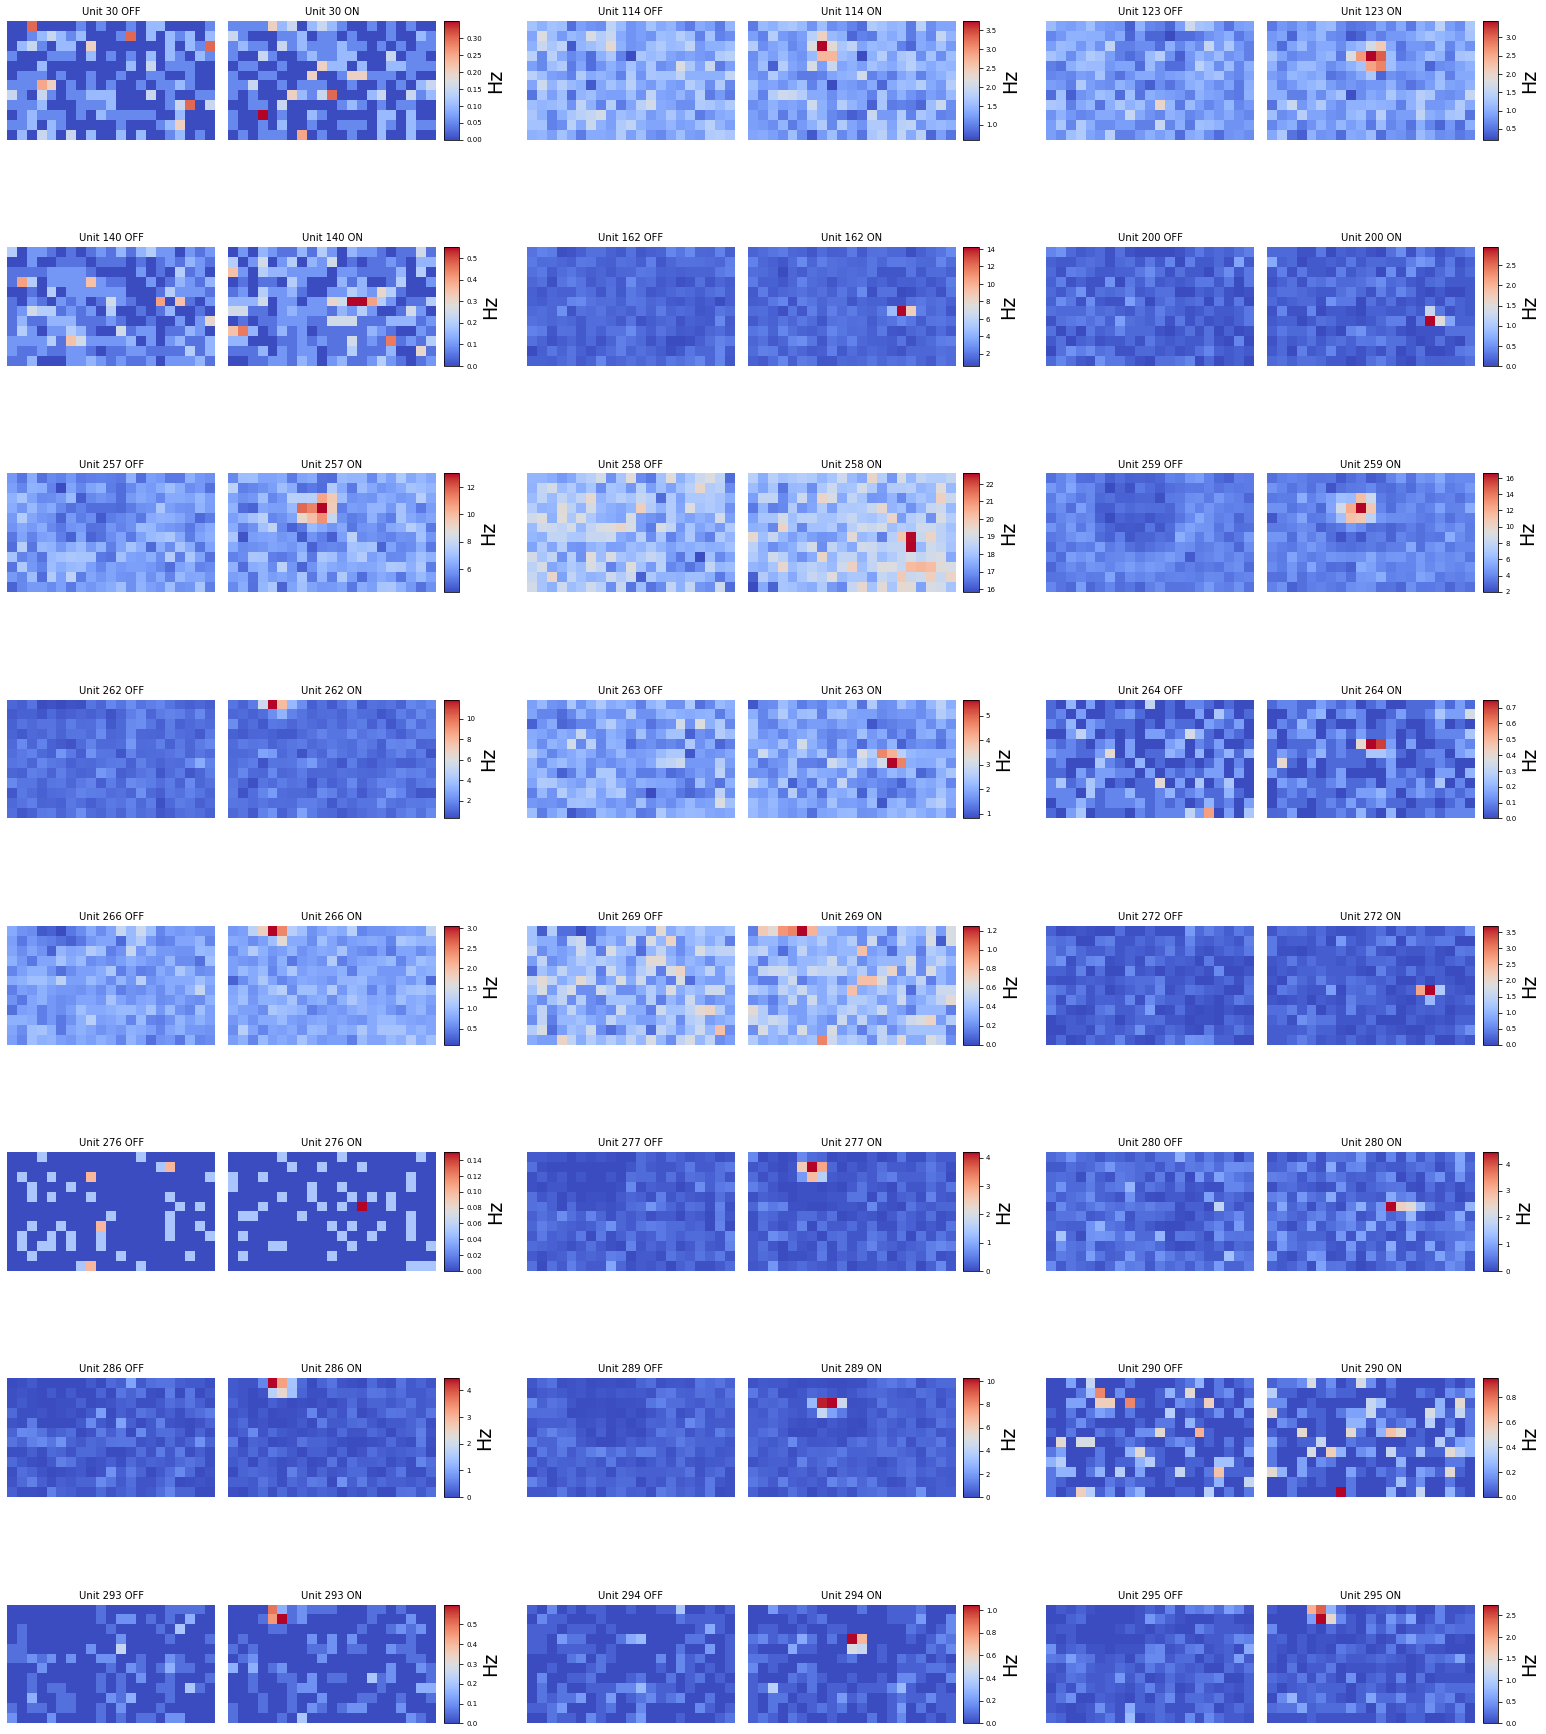

In [37]:
# Plot ON and OFF maps for all units
n_units = len(g_ids)
neurons_per_row = 3
n_rows = int(np.ceil(n_units / neurons_per_row))

fig, axes = plt.subplots(
    n_rows, neurons_per_row * 2,  # OFF + ON per neuron
    figsize=(4.5 * neurons_per_row * 2, 4.0 * n_rows)
)

plt.subplots_adjust(wspace=0.25, hspace=0.45)
if n_rows == 1:
    axes = axes.reshape(1, -1)

for u in range(n_units):

    row = u // neurons_per_row
    col = u % neurons_per_row

    off_ax = axes[row, col * 2]
    on_ax  = axes[row, col * 2 + 1]
    ON_ETA=UNIT_ON_RESPONSES[u]/stim_length
    OFF_ETA=UNIT_OFF_RESPONSES[u]/stim_length
    # To normalize the colorbars
    off_max = np.nanmax(OFF_ETA)
    on_max  = np.nanmax(ON_ETA)
    off_min = np.nanmin(OFF_ETA)
    on_min  = np.nanmin(ON_ETA)

    vmax = max(off_max, on_max)
    vmin = min(off_min, on_min)
    if vmax <= 0:
        vmax = 1e-12

    # OFF ETA
    im_off = off_ax.imshow(OFF_ETA,cmap='coolwarm', vmin=vmin, vmax=vmax)
    off_ax.set_title(f"Unit {g_ids[u]} OFF", fontsize=10)
    off_ax.axis("off")

    # ON ETA
    im_on = on_ax.imshow(ON_ETA,cmap='coolwarm', vmin=vmin, vmax=vmax)
    on_ax.set_title(f"Unit {g_ids[u]} ON", fontsize=10)
    on_ax.axis("off")

    
    # Adjust visualization
    off_bb = off_ax.get_position()
    on_bb  = on_ax.get_position()
    off_ax.set_position([
        off_bb.x0 + 0.01, 
        off_bb.y0,
        off_bb.width,
        off_bb.height
    ])
    on_ax.set_position([
        on_bb.x0 - 0.01,  
        on_bb.y0,
        on_bb.width,
        on_bb.height
    ])
    
    bb = on_ax.get_position()
    cb_width = 0.008
    cb_pad   = 0.004   
    cbar_ax = fig.add_axes([
        bb.x1 + cb_pad,
        bb.y0,
        cb_width,
        bb.height
    ])

    cbar = fig.colorbar(im_on, cax=cbar_ax)
    cbar.ax.tick_params(labelsize=7)
    cbar.set_label('Hz')

plt.show()




In [38]:
n_units = len(g_ids)

ONs = []
NONEs = []
CENTREs = []

for unit in range(n_units):

    # Get ON/OFF Estimated Trigger Averages (ETAs) for this unit
    ON_ETA  = UNIT_ON_RESPONSES[unit]
    OFF_ETA = UNIT_OFF_RESPONSES[unit]

    ON_max  = np.nanmax(ON_ETA)
    OFF_max = np.nanmax(OFF_ETA)

    # Determine ON- or OFF-dominant & RF centre pixel
    if ON_max >= OFF_max:
        # ON-dominant unit
        polarity = "on"
        rf_idx = np.where(ON_ETA == ON_max)
    else:
        # OFF-dominant unit
        polarity = "off"
        rf_idx = np.where(OFF_ETA == OFF_max)

    # If multiple pixels share the max, take the first
    if len(rf_idx[0]) > 1:
        rf_centre = np.asarray([rf_idx[0][0], rf_idx[1][0]])
    else:
        rf_centre = np.asarray([rf_idx[0][0], rf_idx[1][0]])

    CENTREs.append(rf_centre)

    # Extract stimulus indices for ON or OFF peaks
    if polarity == "on":
        pos_idxs = np.where(sparse_noise_matrix[:, rf_centre[0], rf_centre[1]] == 1)[0]
    else:
        pos_idxs = np.where(sparse_noise_matrix[:, rf_centre[0], rf_centre[1]] == -1)[0]

    # Baseline (zero-neighborhood)
    zero_idxs = find_zero_neighborhood_indexes_with_previous(
        sparse_noise_matrix, rf_centre, neighborhood_size=4
    )

    # Extract firing rates for these stims
    unit_spikes = stim_unit_FRs[unit]

    stim_on_vals   = unit_spikes[pos_idxs]   if len(pos_idxs)   > 0 else np.array([0.0])
    stim_zero_vals = unit_spikes[zero_idxs] if len(zero_idxs) > 0 else np.array([0.0])

    # mean spike count per stim, then convert to Hz
    stim_on = np.nansum(stim_on_vals)   / len(stim_on_vals)
    stim_on = stim_on / stim_length

    stim_none = np.nansum(stim_zero_vals) / len(stim_zero_vals)
    stim_none = stim_none / stim_length

    # avoid division issues
    if stim_none < 0.001:
        stim_none = 0.001

    ONs.append(stim_on)
    NONEs.append(stim_none)

# Convert to arrays
ONs     = np.asarray(ONs)
NONEs   = np.asarray(NONEs)
CENTREs = np.asarray(CENTREs, dtype="object")



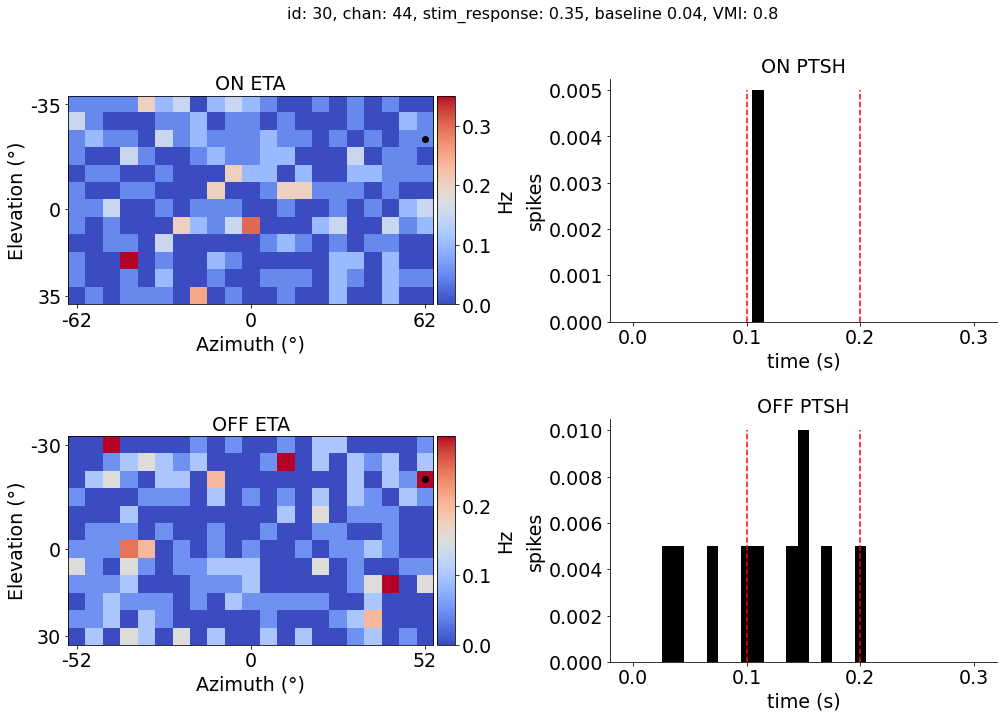

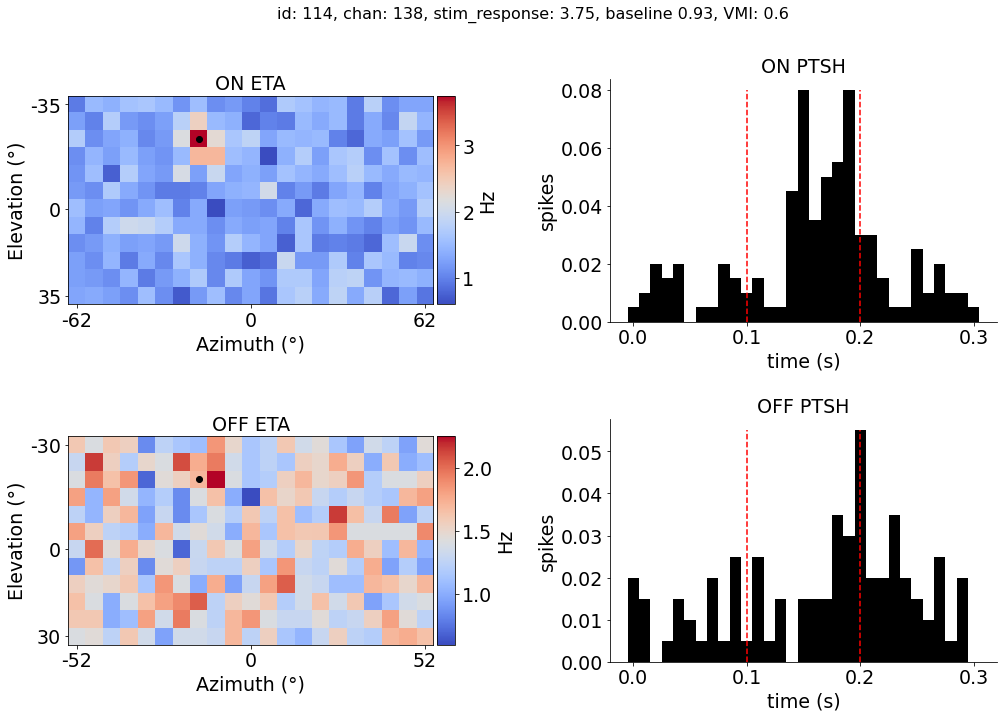

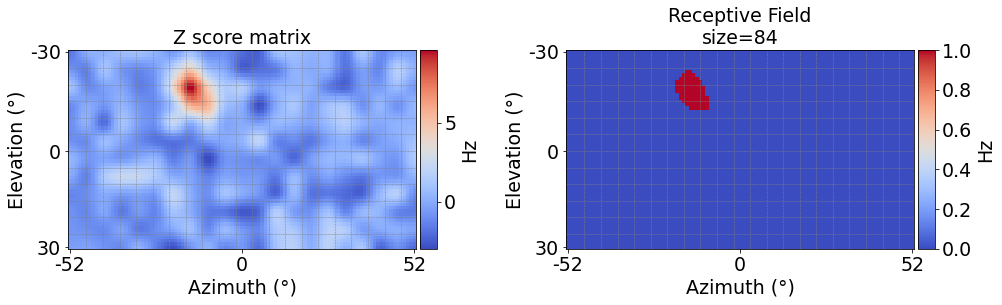

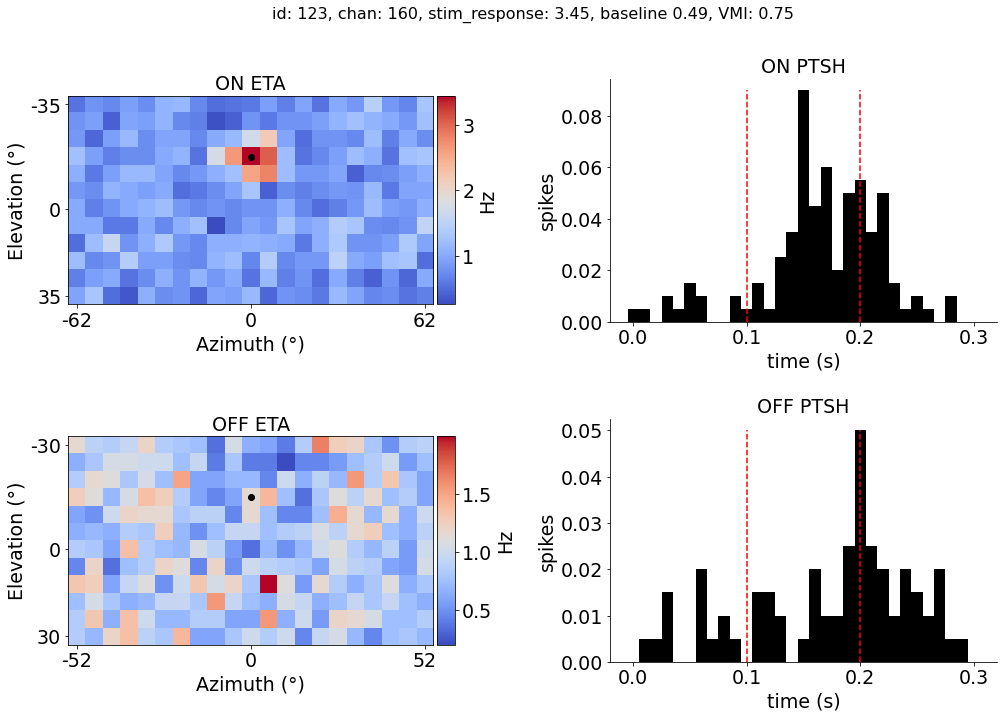

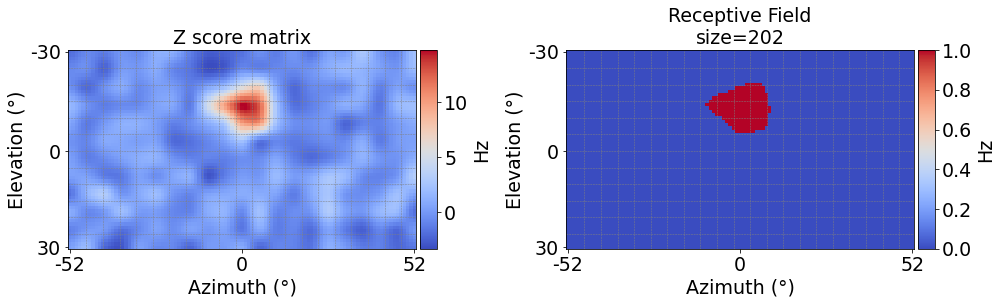

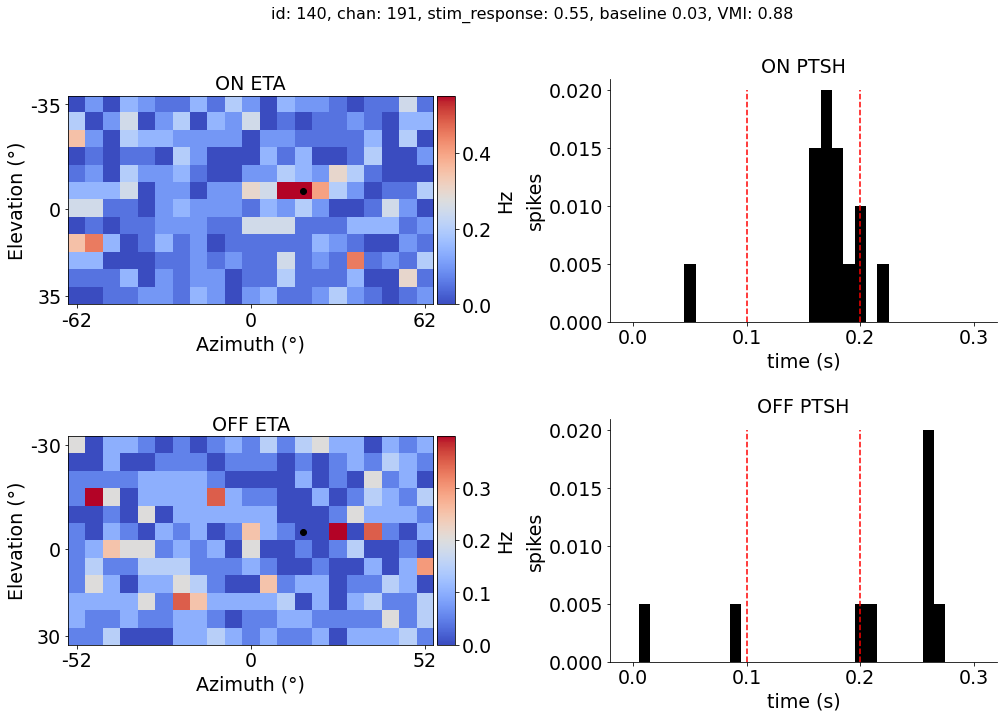

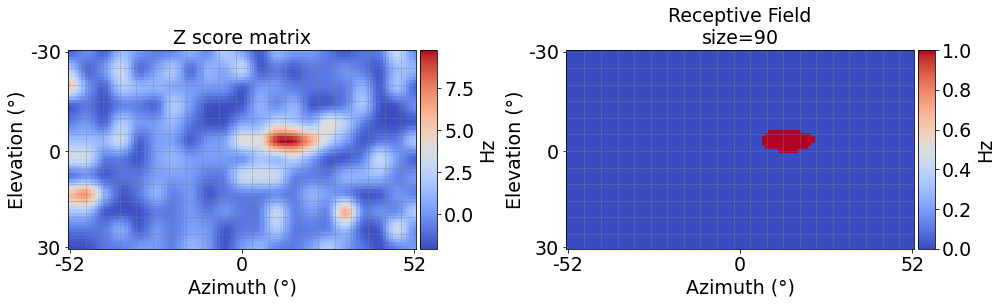

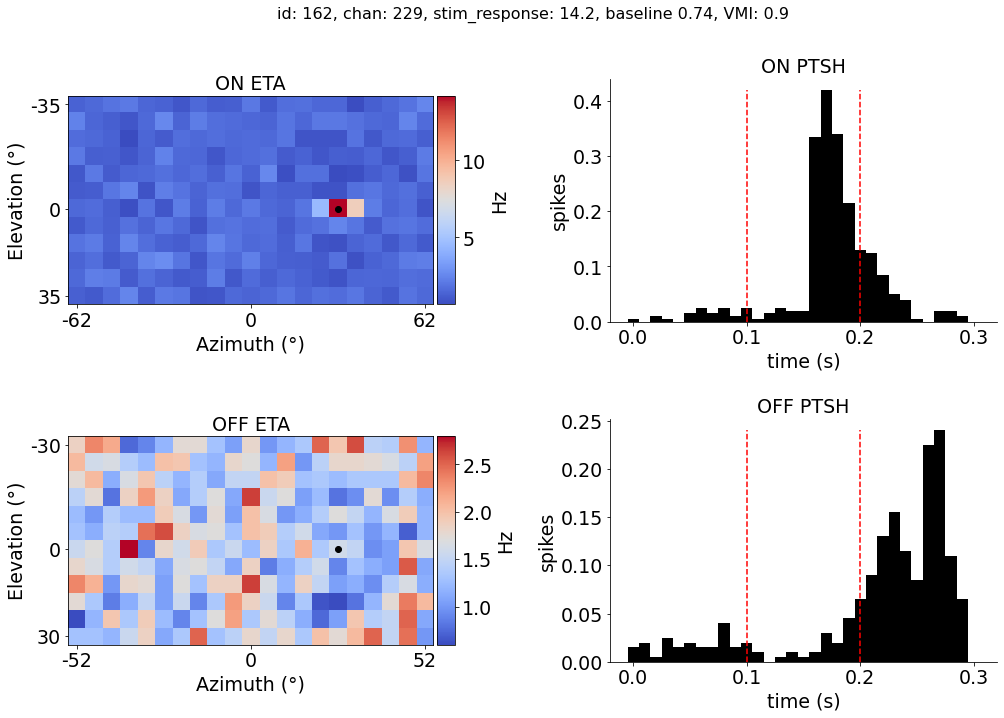

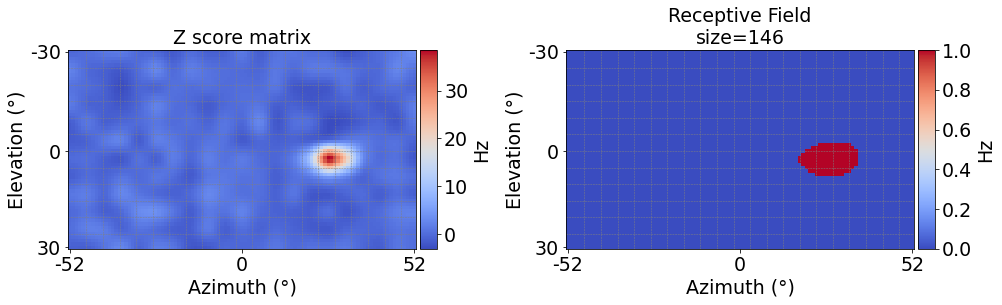

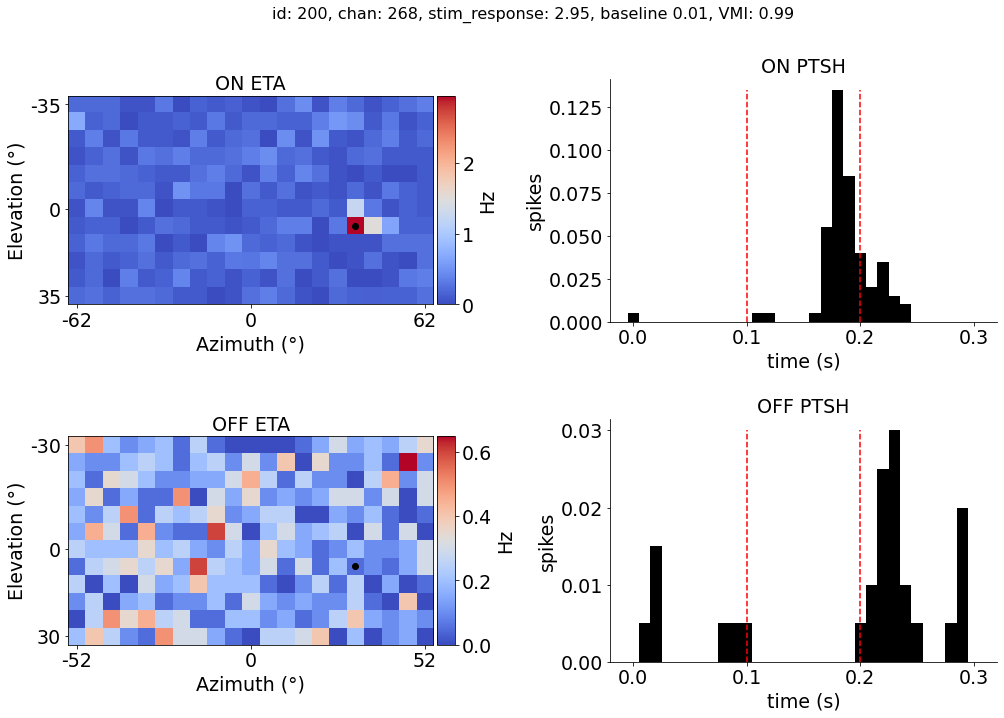

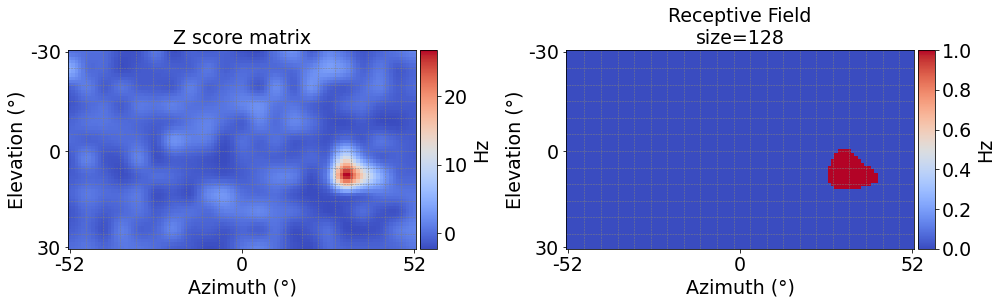

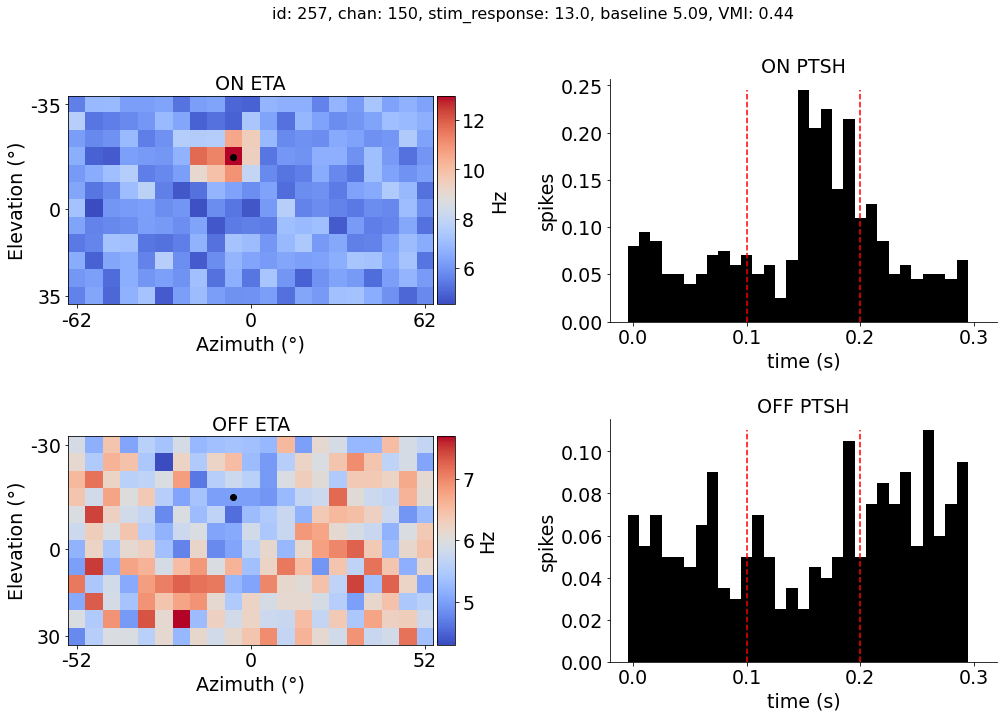

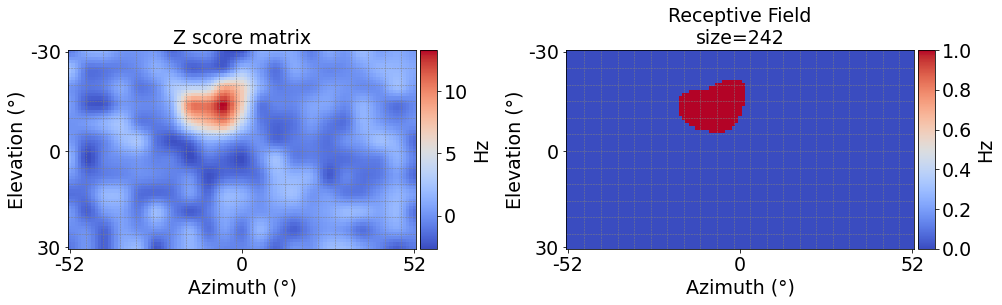

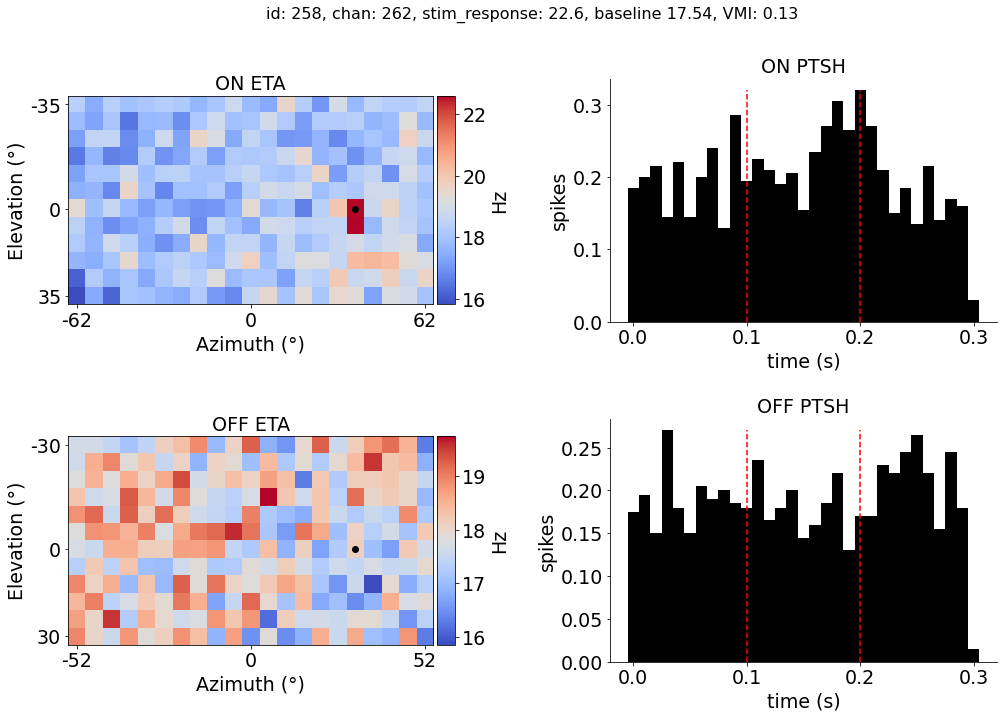

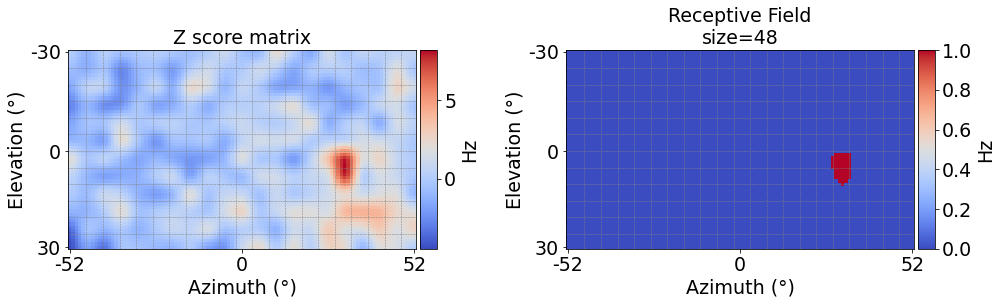

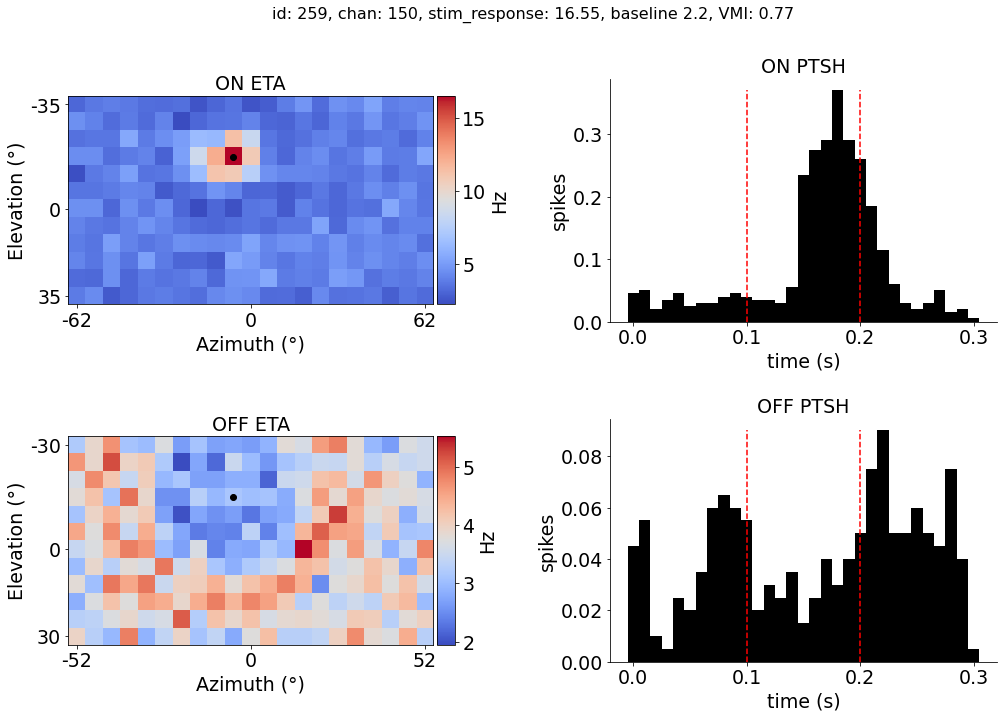

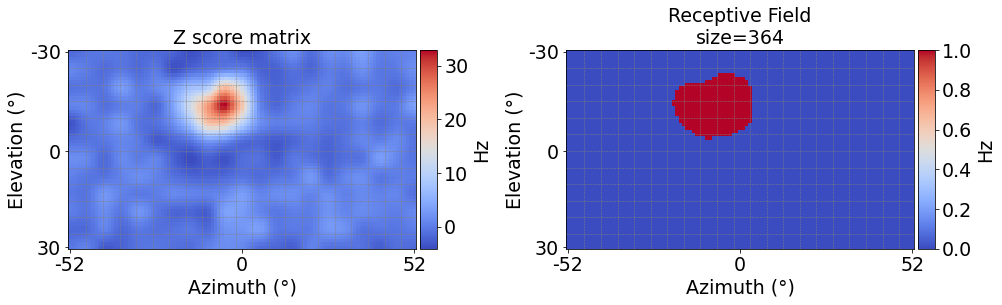

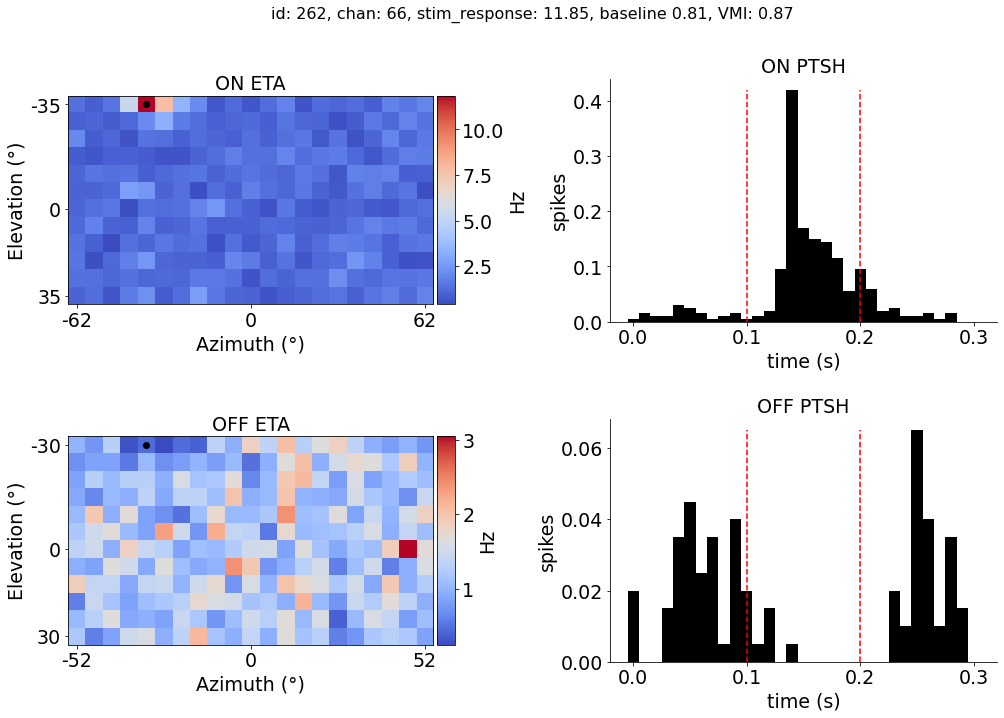

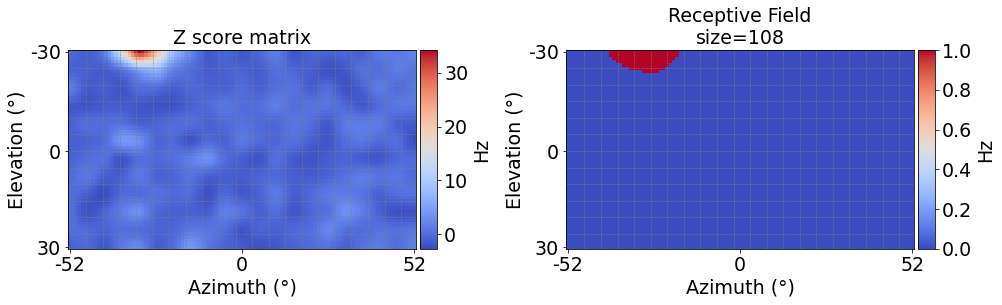

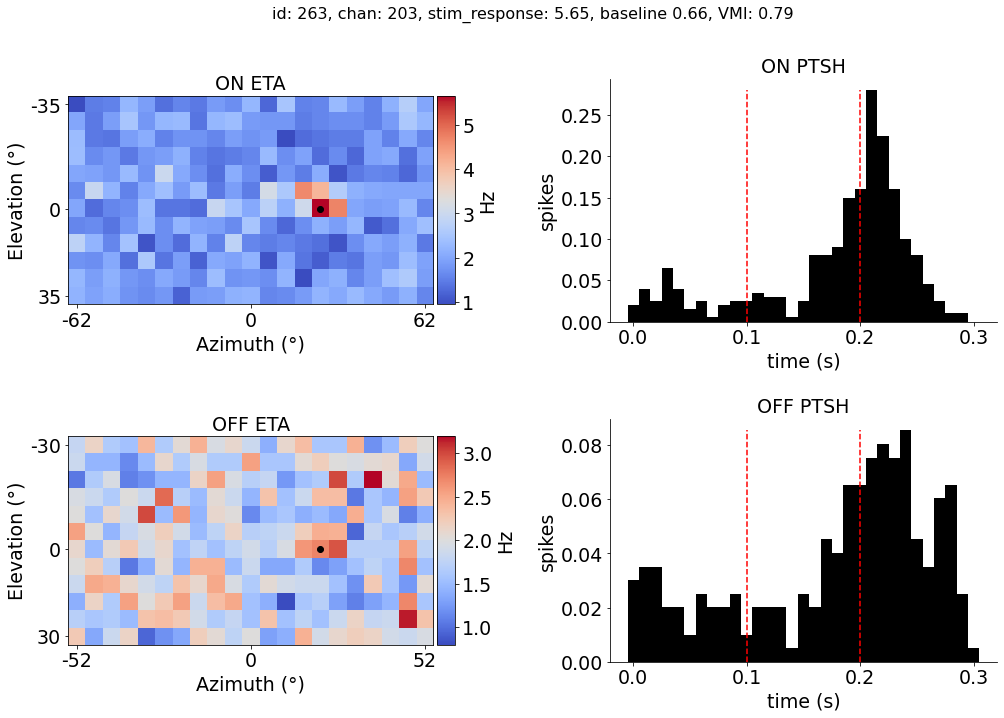

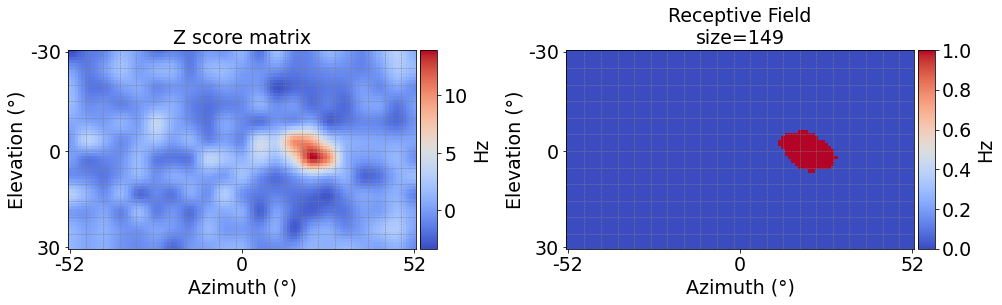

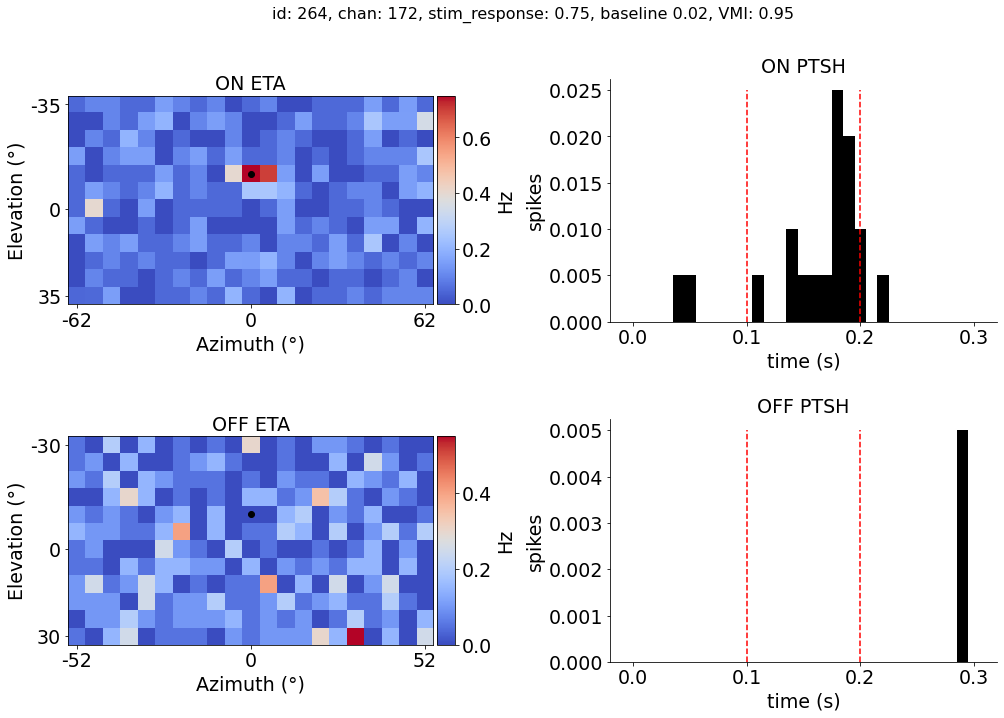

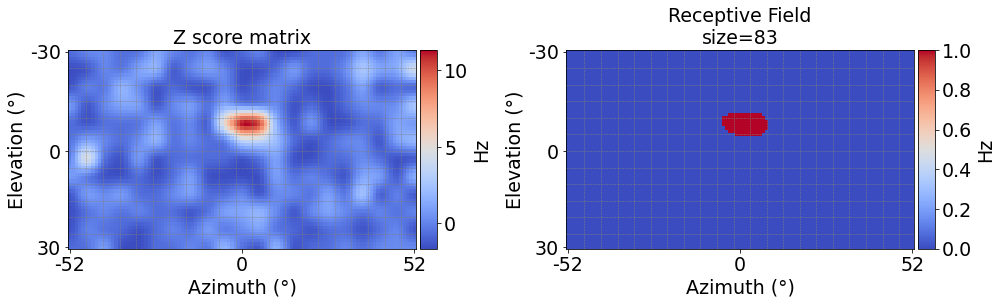

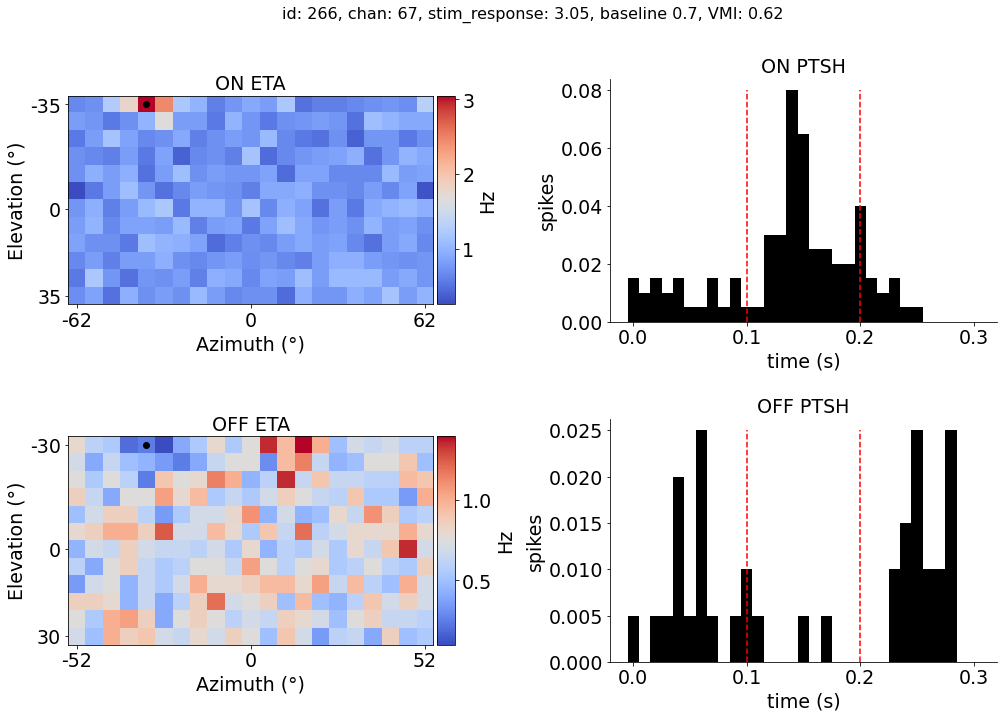

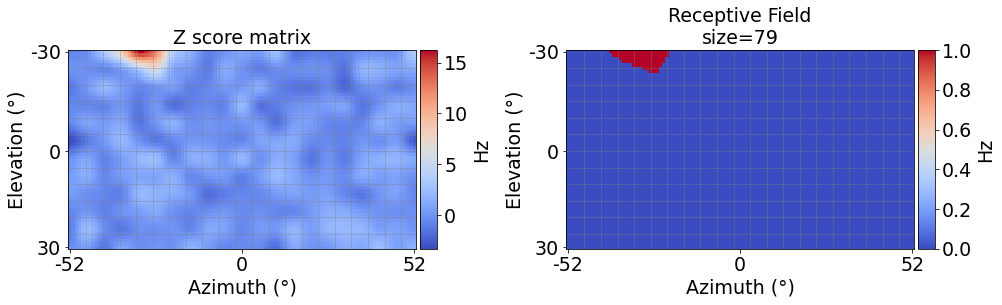

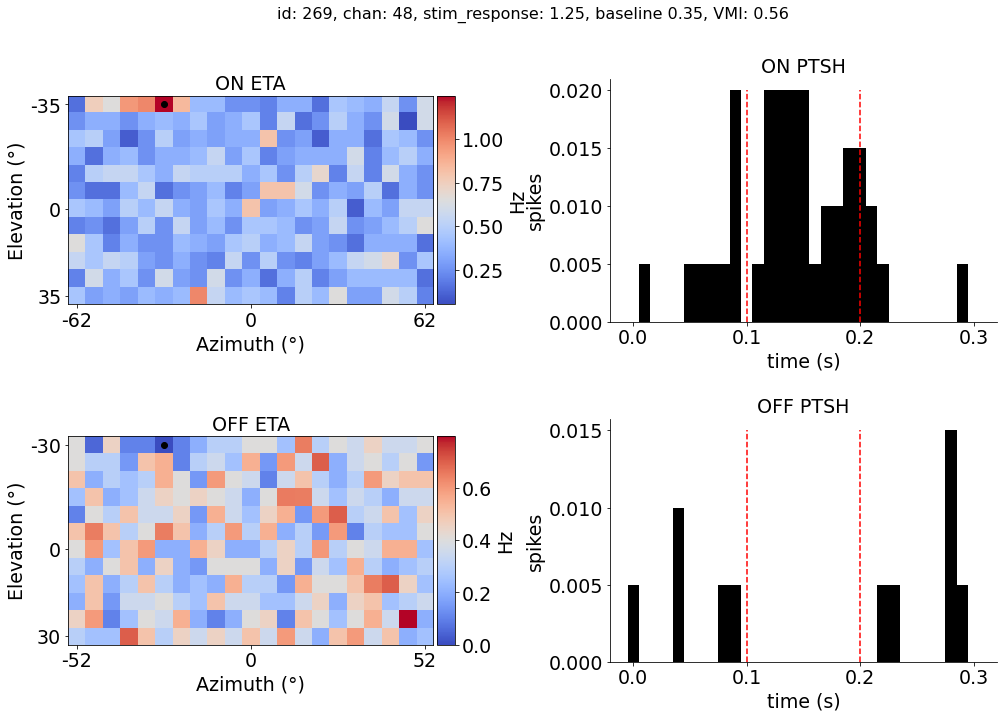

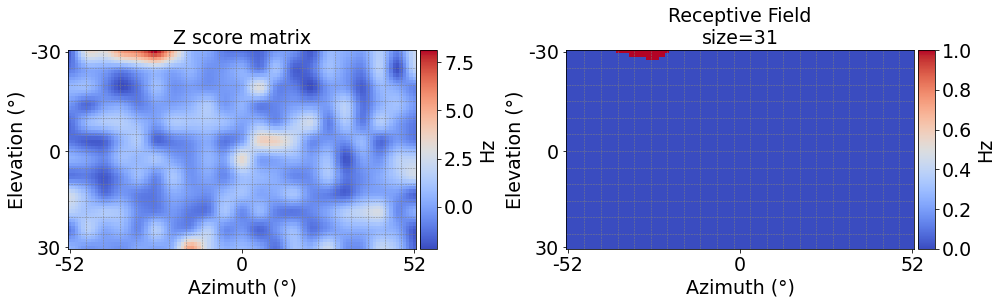

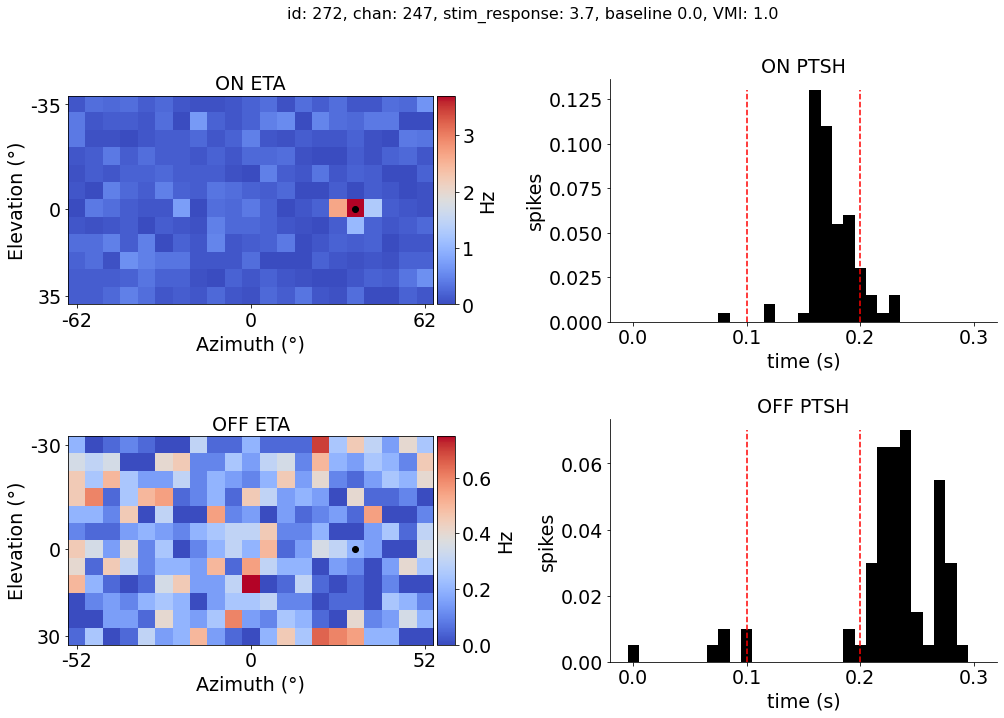

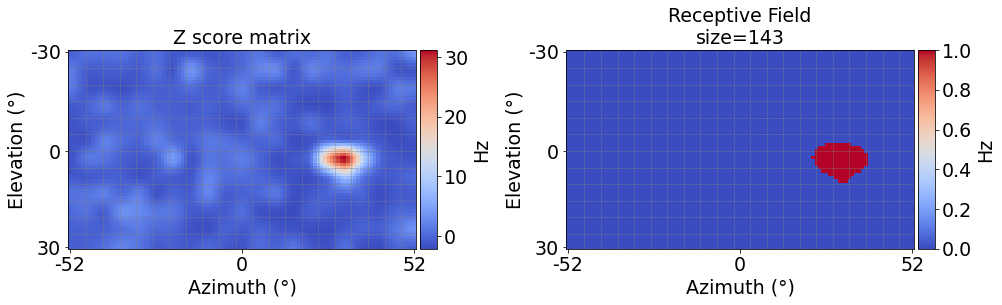

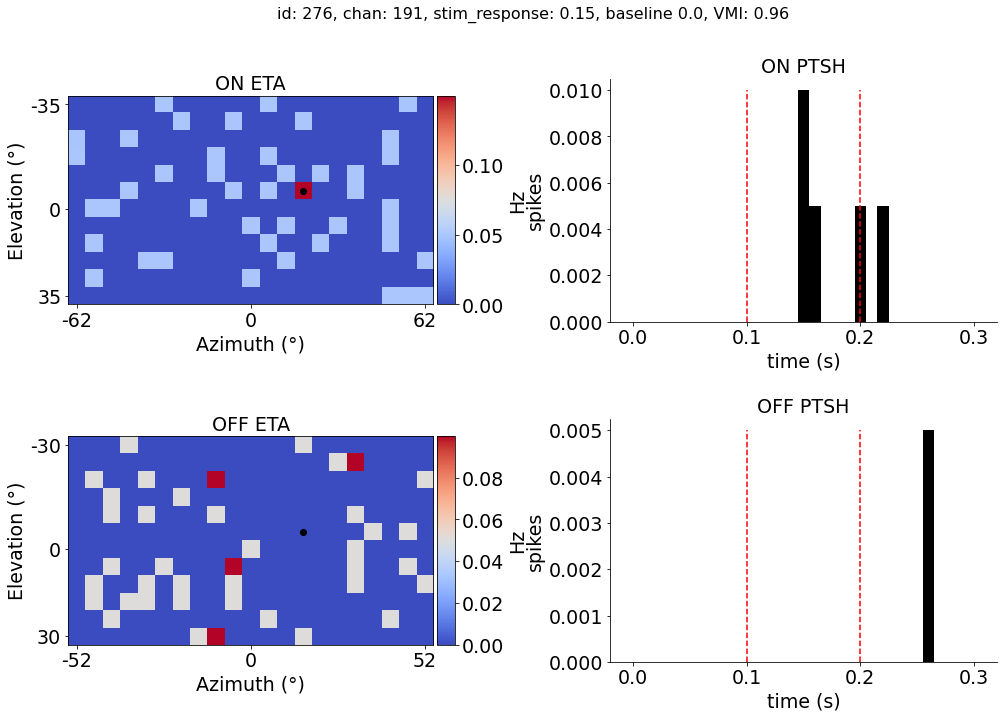

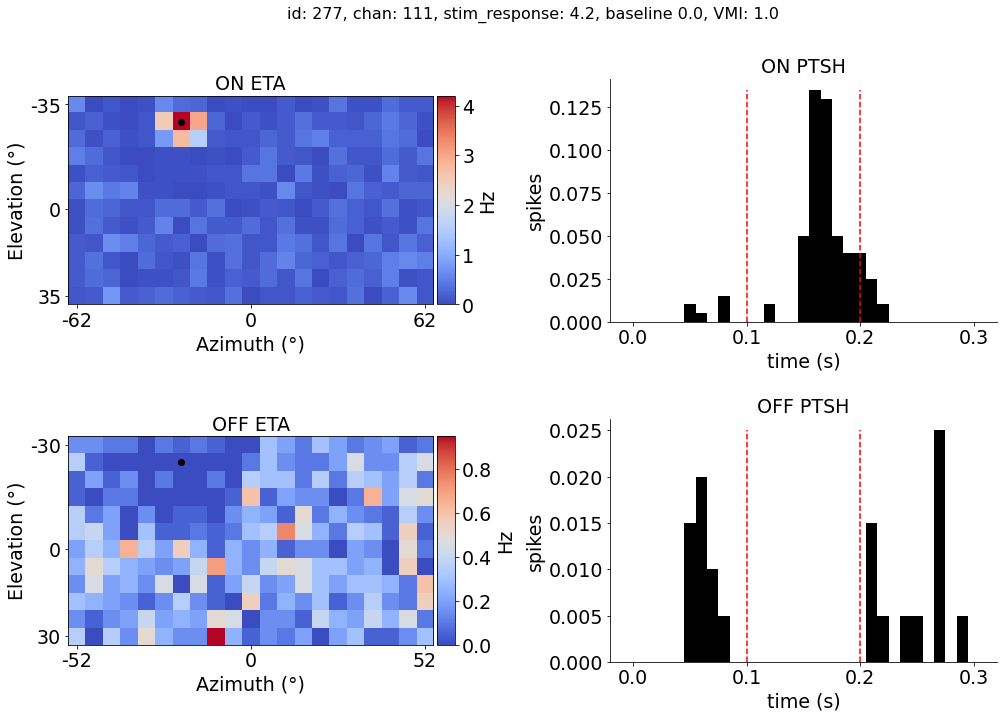

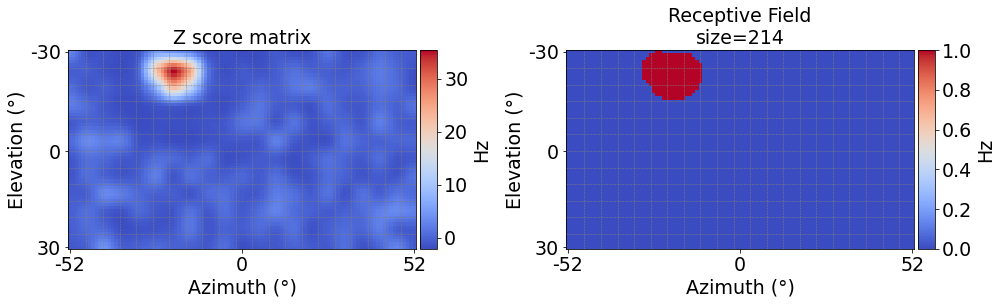

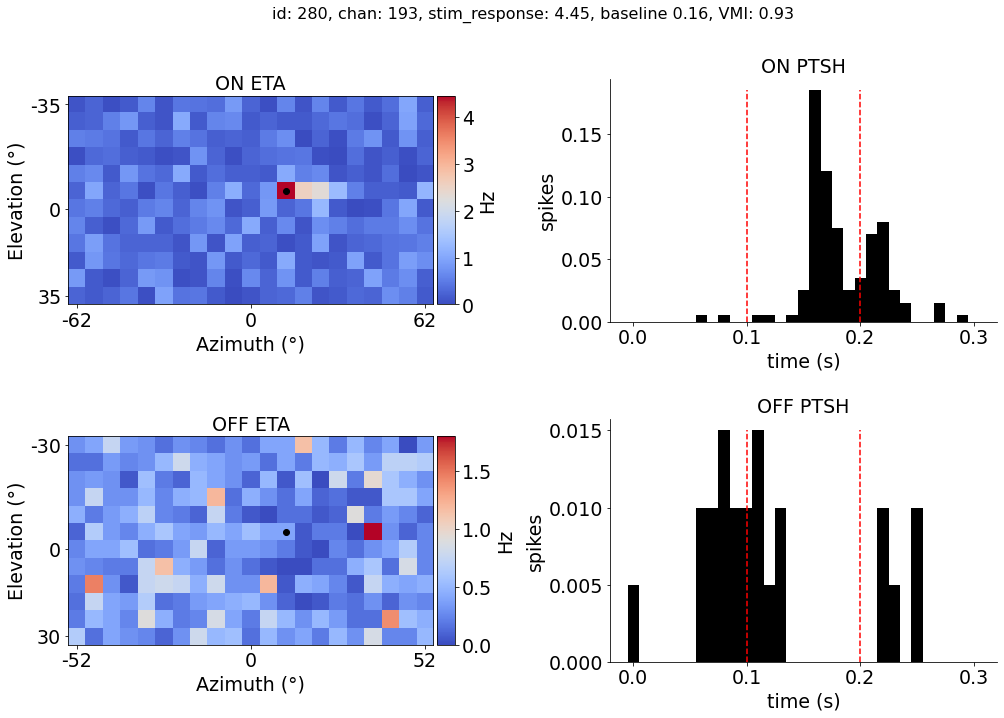

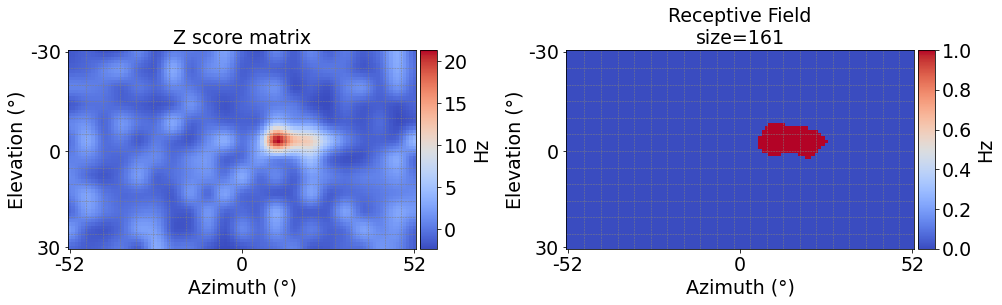

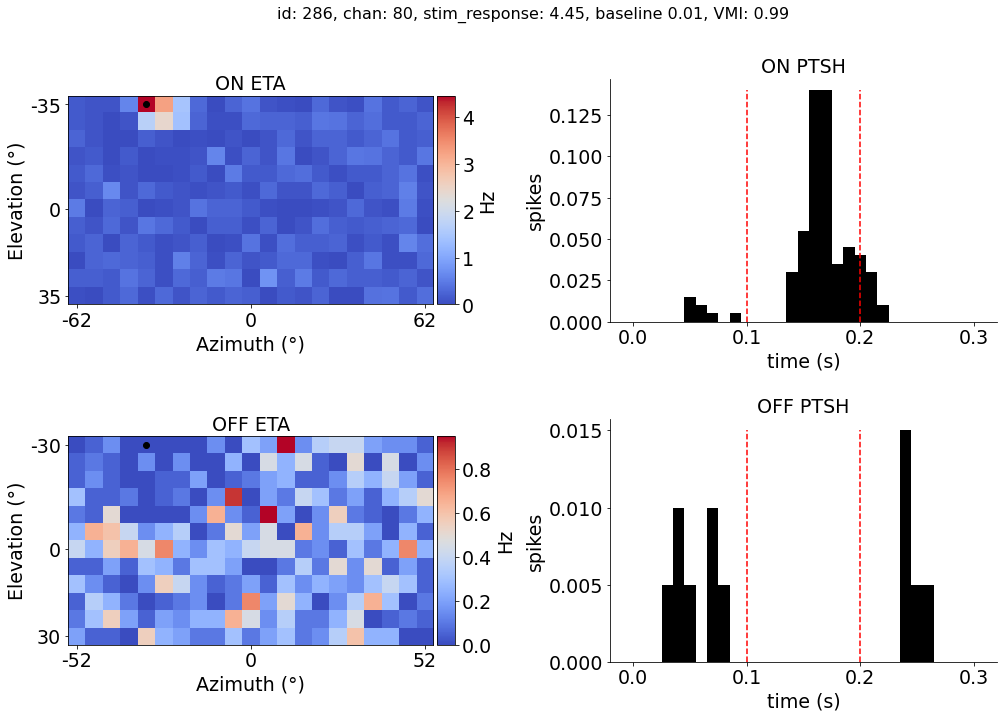

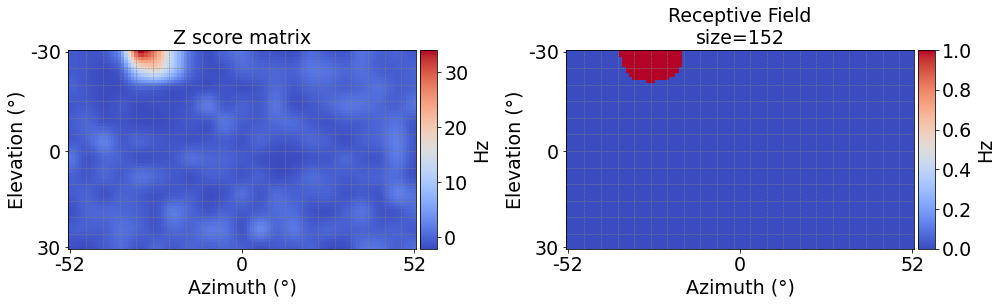

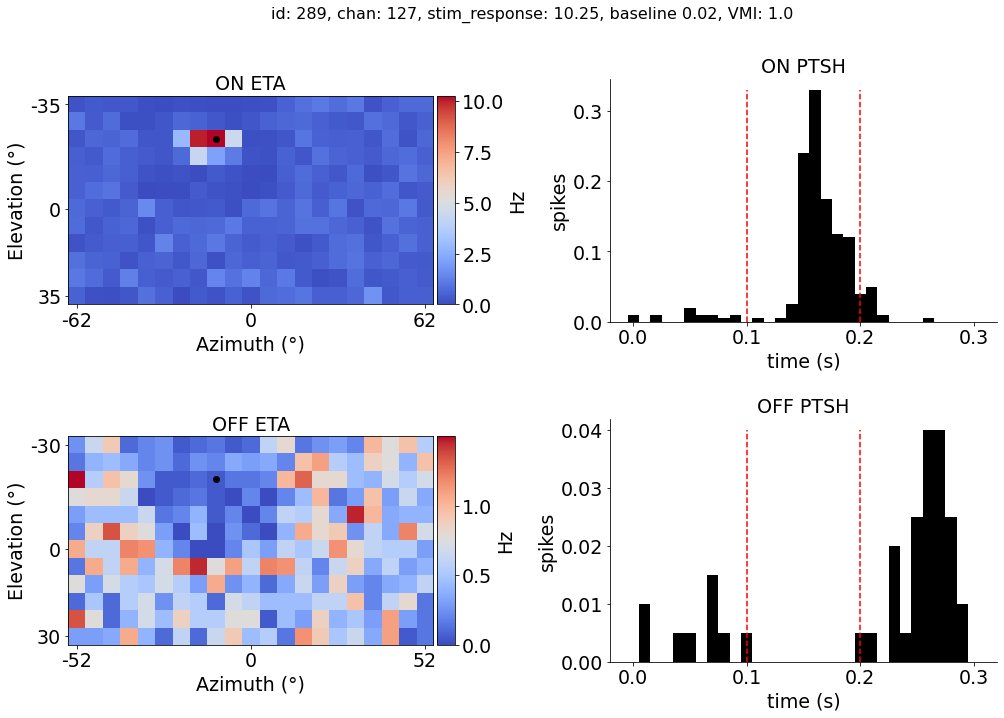

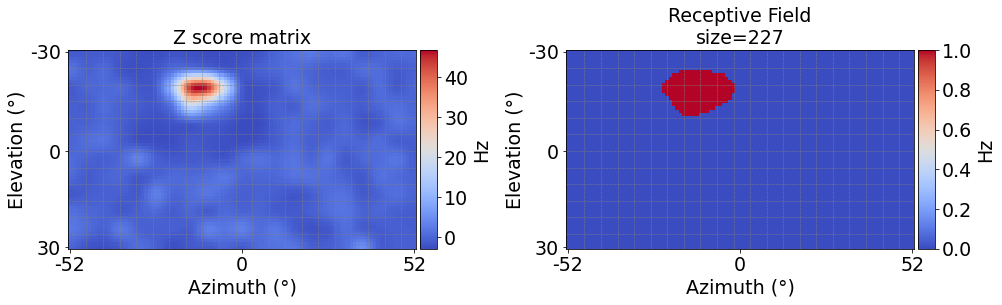

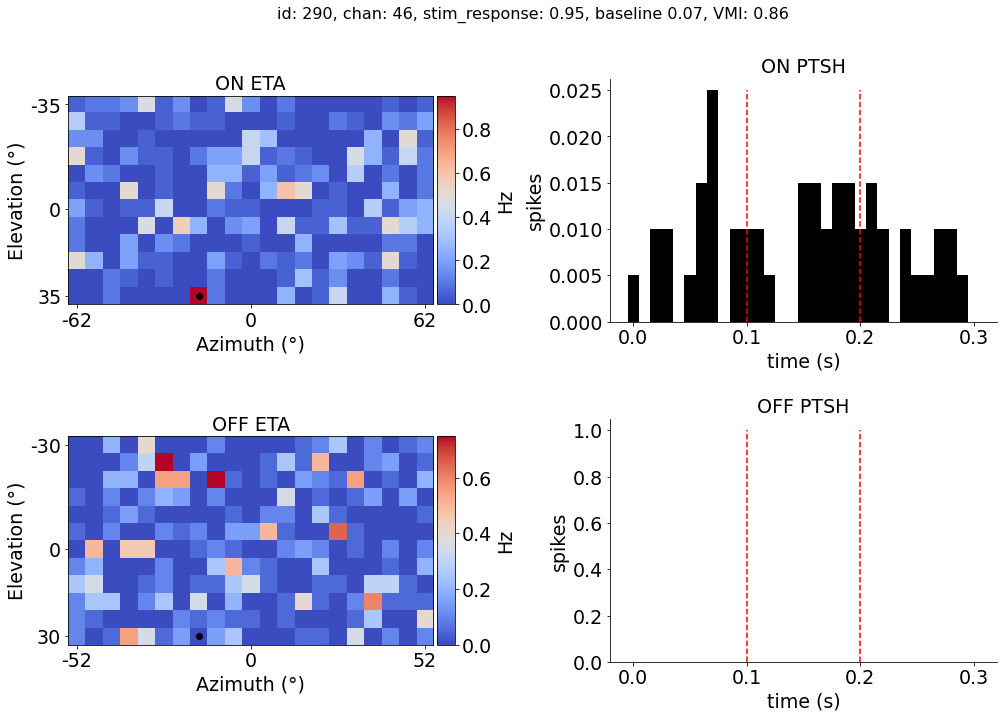

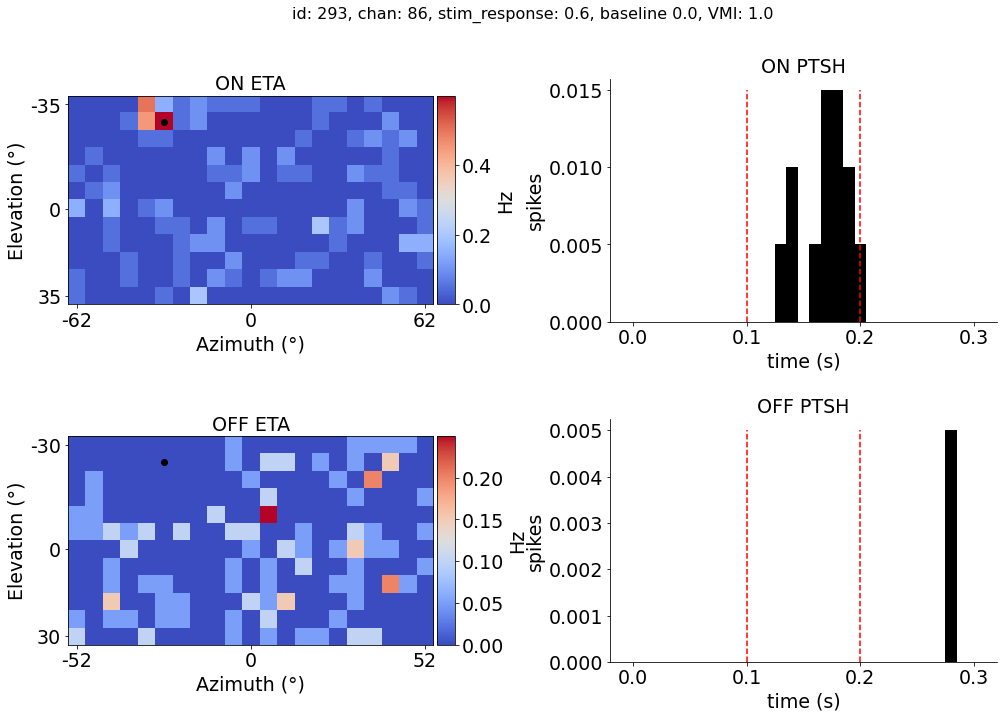

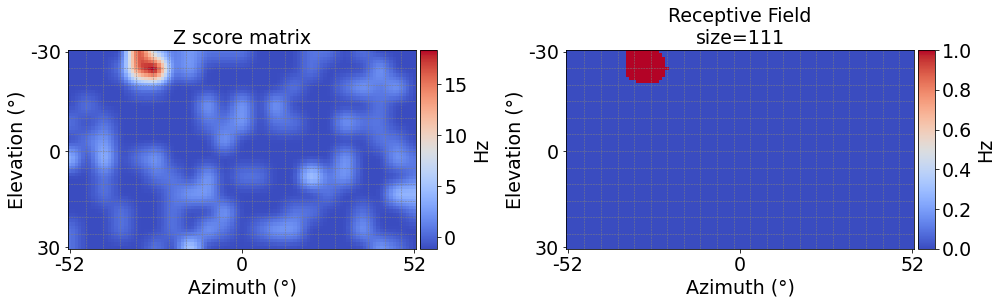

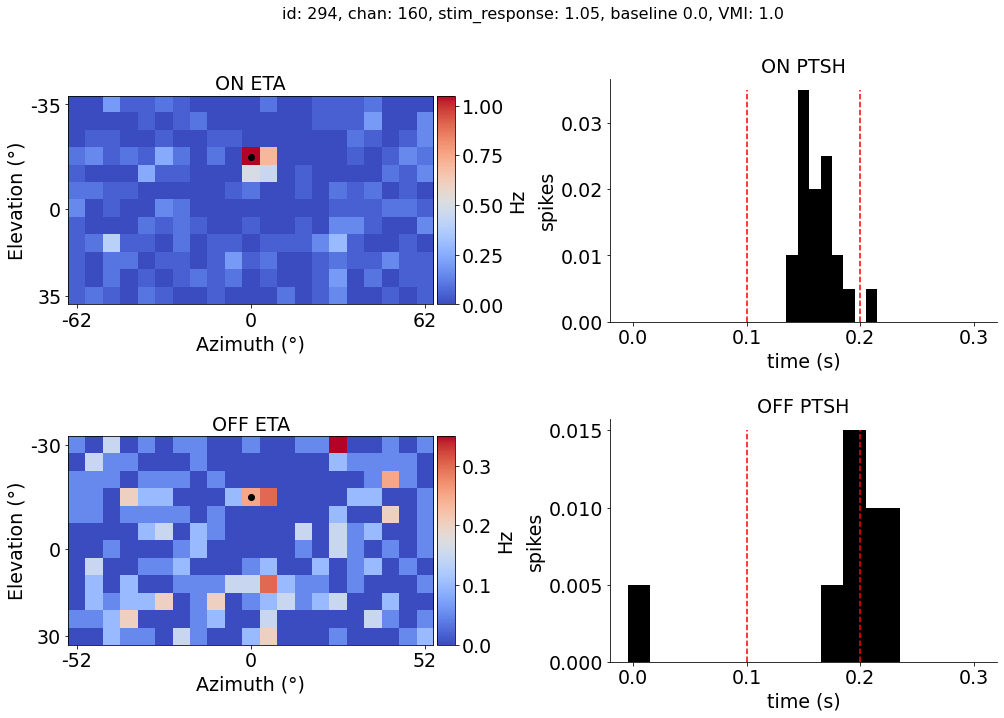

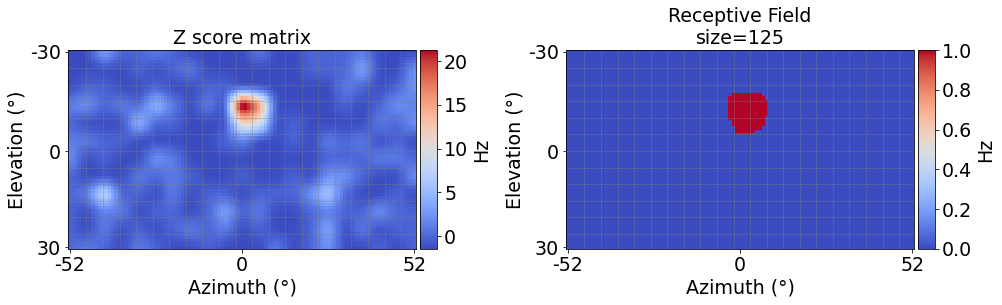

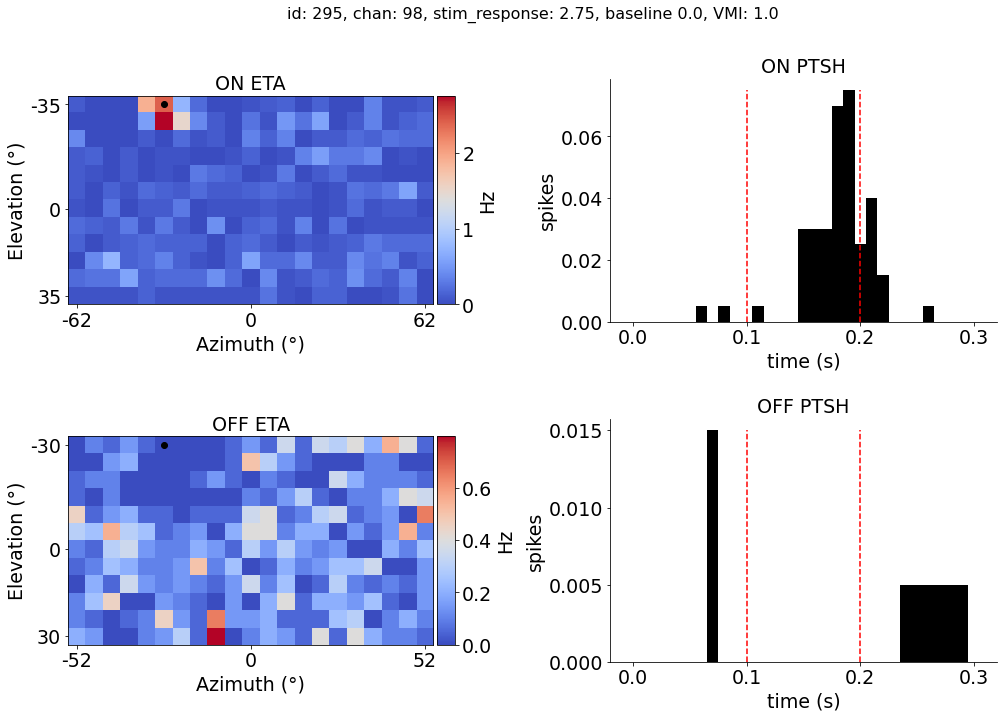

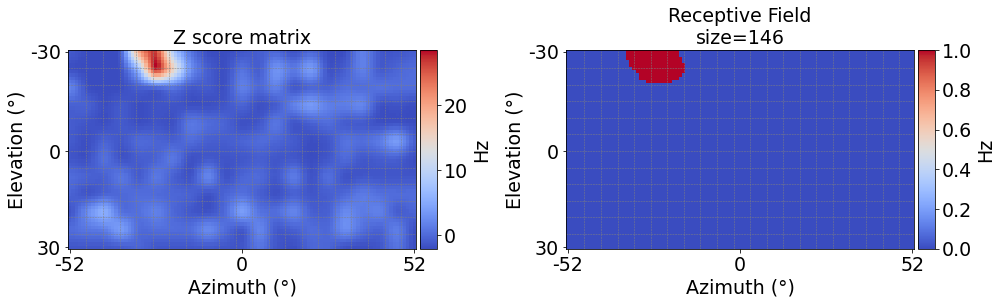

In [39]:
# RF analysis 
up_factor   = 5
PEAK_THRESH = 5
BLOB_THRESH = 5
BIN_SIZE    = 0.01

SIZES   = []
CENTERS = []
DIAMS   = []

STIM_LENGTH = np.mean(np.diff(stim_windows, axis=1))
EXTENSION   = STIM_LENGTH

# Use the same sparse noise matrix you used for ON/OFF computation
SN_MATRIX = sparse_noise_matrix   # shape: (n_stim, H, W)

for unit in range(len(g_ids)):

    SPIKES   = spike_t_matrix[unit]  # times in seconds
    ON_MAT   = UNIT_ON_RESPONSES[unit]
    OFF_MAT  = UNIT_OFF_RESPONSES[unit]
    ON_NULL  = UNIT_ON_RESPONSES_NULL[unit]
    OFF_NULL = UNIT_OFF_RESPONSES_NULL[unit]

    #  Get RF PSTHs & center 
    ON_HIST, OFF_HIST, time_bins, RF_CENT, is_on = get_rf_PTSH(
        SN_MATRIX, ON_MAT, OFF_MAT, SPIKES,
        stim_windows, STIM_LENGTH, EXTENSION,
        bin_size=BIN_SIZE
    )

    border_flag = (0 in RF_CENT)

    # FIGURE 1: ON/OFF maps + PSTHs
    fig, ax = plt.subplots(2, 2, figsize=(15, 10))

    # adjust spacing instead of tight_layout
    fig.subplots_adjust(left=0.07, right=0.93,
                        bottom=0.07, top=0.88,
                        wspace=0.4, hspace=0.4)

    H, W = ON_MAT.shape
    yticks_pix = [0, H // 2, H - 1]
    xticks_pix = [0, W // 2, W - 1]

    # ---- ON matrix ----
    im_on = ax[0, 0].imshow(ON_MAT / STIM_LENGTH, cmap='coolwarm')
    ax[0, 0].scatter(RF_CENT[1], RF_CENT[0], color='black')

    # colorbar with same height as imshow
    divider_on = make_axes_locatable(ax[0, 0])
    cax_on = divider_on.append_axes("right", size="5%", pad=0.05)
    cbar_on = fig.colorbar(im_on, cax=cax_on)
    cbar_on.set_label("Hz")

    ax[0, 0].set_xticks(xticks_pix)
    ax[0, 0].set_yticks(yticks_pix)
    ax[0, 0].set_xticklabels([-62, 0, +62])
    ax[0, 0].set_yticklabels([-35, 0, +35])
    ax[0, 0].set_xlabel('Azimuth (°)')
    ax[0, 0].set_ylabel('Elevation (°)')
    ax[0, 0].set_title('ON ETA')

    # ---- ON PSTH ----
    ax[0, 1].bar(time_bins[:-1], ON_HIST, width=BIN_SIZE, color='black')
    ax[0, 1].vlines([0.1, 0.2], 0,
                    np.max(ON_HIST) if np.max(ON_HIST) > 0 else 1,
                    linestyle='dashed', color='red')
    ax[0, 1].spines['top'].set_visible(False)
    ax[0, 1].spines['right'].set_visible(False)
    ax[0, 1].set_xlabel('time (s)')
    ax[0, 1].set_ylabel('spikes')
    ax[0, 1].set_title('ON PTSH')

    # ---- OFF matrix ----
    im_off = ax[1, 0].imshow(OFF_MAT / STIM_LENGTH, cmap='coolwarm')
    ax[1, 0].scatter(RF_CENT[1], RF_CENT[0], color='black')

    # colorbar with same height as imshow
    divider_off = make_axes_locatable(ax[1, 0])
    cax_off = divider_off.append_axes("right", size="5%", pad=0.05)
    cbar_off = fig.colorbar(im_off, cax=cax_off)
    cbar_off.set_label("Hz")

    ax[1, 0].set_xticks(xticks_pix)
    ax[1, 0].set_yticks(yticks_pix)
    ax[1, 0].set_xticklabels([-52, 0, +52])
    ax[1, 0].set_yticklabels([-30, 0, +30])
    ax[1, 0].set_xlabel('Azimuth (°)')
    ax[1, 0].set_ylabel('Elevation (°)')
    ax[1, 0].set_title('OFF ETA')

    # ---- OFF PSTH ----
    ax[1, 1].bar(time_bins[:-1], OFF_HIST, width=BIN_SIZE, color='black')
    ax[1, 1].vlines([0.1, 0.2], 0,
                    np.max(OFF_HIST) if np.max(OFF_HIST) > 0 else 1,
                    linestyle='dashed', color='red')
    ax[1, 1].spines['top'].set_visible(False)
    ax[1, 1].spines['right'].set_visible(False)
    ax[1, 1].set_xlabel('time (s)')
    ax[1, 1].set_ylabel('spikes')
    ax[1, 1].set_title('OFF PTSH')

    vis_mod = (ONs[unit] - NONEs[unit]) / (ONs[unit] + NONEs[unit])

    fig.suptitle(
        f'id: {g_ids[unit]}, chan: {g_channels[unit]}, '
        f'stim_response: {np.round(ONs[unit], 2)}, baseline {np.round(NONEs[unit], 2)}, '
        f'VMI: {np.round(vis_mod, 2)}',
        fontsize=16
    )
    plt.show()



    ON_BLOB, ON_SIZE, ON_LOC, ON_FILT_ETA, ON_STD_ETA, ON_RF_DIAMETER, \
        ON_RF_PEAKRATE, ON_RF_MINRATE, ON_POS = calc_rf(
            ON_MAT, ON_NULL,
            peak_thresh=PEAK_THRESH,
            blob_thresh=BLOB_THRESH,
            gaus_f=1,
            med_f=1,
            upsample=up_factor,
            force_polarity=None
    )
    if ON_SIZE>25:
        
        ON_LOC = np.round(np.asarray(ON_LOC) / up_factor, 2)

        fig, ax = plt.subplots(1, 2, figsize=(14, 6))

        fig.subplots_adjust(left=0.07, right=0.93,
                            bottom=0.1, top=0.9,
                            wspace=0.35)

        # LEFT: z-scored filtered ETA 
        im = ax[0].imshow(ON_FILT_ETA / ON_STD_ETA, cmap='coolwarm')
        ax[0].set_title(f"Z score matrix")

        # colorbar with same height as imshow
        divider_sta = make_axes_locatable(ax[0])
        cax_sta = divider_sta.append_axes("right", size="5%", pad=0.05)
        cbar_sta = fig.colorbar(im, cax=cax_sta)
        cbar_sta.set_label("Hz")

        zoom_factor = ON_BLOB.shape[0] / ON_MAT.shape[0]
        for i in range(1, ON_MAT.shape[0]):
            ax[0].axhline(i * zoom_factor, color='gray',
                          linestyle='--', linewidth=0.5)
        for j in range(1, ON_MAT.shape[1]):
            ax[0].axvline(j * zoom_factor, color='gray',
                          linestyle='--', linewidth=0.5)

        # RIGHT: RF MASK
        im2 = ax[1].imshow(ON_BLOB, cmap='coolwarm')
        ax[1].set_title(f"Receptive Field\nsize={ON_SIZE}")

        # colorbar with same height as imshow
        divider_blob = make_axes_locatable(ax[1])
        cax_blob = divider_blob.append_axes("right", size="5%", pad=0.05)
        cbar_blob = fig.colorbar(im2, cax=cax_blob)
        cbar_blob.set_label("Hz")

        for i in range(1, ON_MAT.shape[0]):
            ax[1].axhline(i * zoom_factor, color='gray',
                          linestyle='--', linewidth=0.5)
        for j in range(1, ON_MAT.shape[1]):
            ax[1].axvline(j * zoom_factor, color='gray',
                          linestyle='--', linewidth=0.5)

        # --- Custom degree ticks ---
        H_up, W_up = ON_FILT_ETA.shape
        yticks_up = [0, H_up // 2, H_up - 1]
        xticks_up = [0, W_up // 2, W_up - 1]

        for a in ax:
            a.set_xticks(xticks_up)
            a.set_yticks(yticks_up)
            a.set_xticklabels([-52, 0, +52])
            a.set_yticklabels([-30, 0, +30])
            a.set_xlabel('Azimuth (°)')
            a.set_ylabel('Elevation (°)')

        plt.show()

    # Store RF info
    if not border_flag:
        SIZES.append(ON_SIZE)
        CENTERS.append(ON_LOC)
        DIAMS.append(ON_RF_DIAMETER)
    else:
        SIZES.append(ON_SIZE)
        CENTERS.append(np.nan)
        DIAMS.append(np.nan)


